In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Inspecting

In [3]:
data=pd.read_csv("D:/Extract here/Iris.csv")
data.head()

,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width,Species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal_Length  150 non-null    float64
 1   Sepal_Width   150 non-null    float64
 2   Petal_Length  150 non-null    float64
 3   Petal_Width   150 non-null    float64
 4   Species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [5]:
data.describe()

,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


#### Insepting
    1.150 records :0 to 149 indexing
    2.4 columns are float64 (columns_name) 1 str column (Species)
    3.5 columns are there
    4. 0 Null values
    5. Total memory 6.0kb

#### Cleansing

In [6]:
data.isnull().sum()

Sepal_Length    0
Sepal_Width     0
Petal_Length    0
Petal_Width     0
Species         0
dtype: int64

In [7]:
data.duplicated().sum()

np.int64(3)

In [8]:
data[data.duplicated()]

,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width,Species
34,4.9,3.1,1.5,0.1,Setosa
37,4.9,3.1,1.5,0.1,Setosa
142,5.8,2.7,5.1,1.9,Virginica


In [9]:
data['Species'].unique()

<StringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str

In [10]:
data['Species'].value_counts()

Species
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

In [11]:
data2=data.drop_duplicates()
data2.info()

<class 'pandas.DataFrame'>
Index: 147 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal_Length  147 non-null    float64
 1   Sepal_Width   147 non-null    float64
 2   Petal_Length  147 non-null    float64
 3   Petal_Width   147 non-null    float64
 4   Species       147 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.9 KB


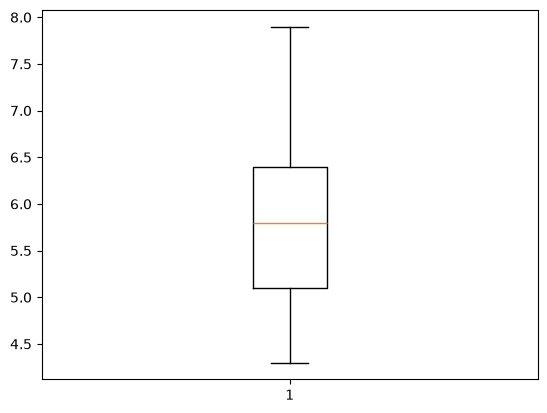

In [12]:
plt.boxplot(data['Sepal_Length'])
plt.show()

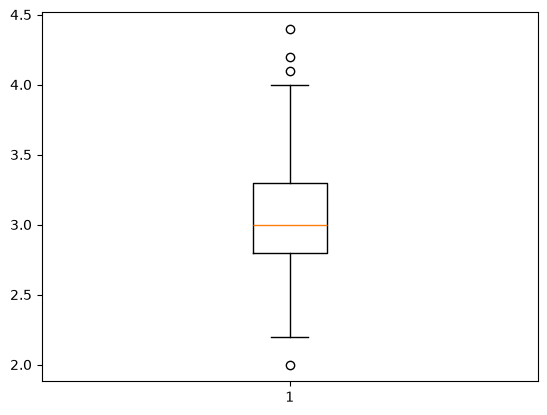

In [13]:
plt.boxplot(data['Sepal_Width'])    #outlier ko remove krna hai ya replace karna hai
plt.show()

In [14]:
q3=data['Sepal_Width'].quantile(0.75)
q1=data['Sepal_Width'].quantile(0.25)

In [15]:
iqr=q3-q1

In [16]:
lb= q1 - 1.5 *iqr
ub= q3 + 1.5 * iqr

In [17]:
data['Sepal_Width']<lb

0      False
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Name: Sepal_Width, Length: 150, dtype: bool

In [18]:
data[data['Sepal_Width']<lb]

,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width,Species
60,5.0,2.0,3.5,1.0,Versicolor


In [19]:
data[(data['Sepal_Width']<lb) | (data['Sepal_Width']>ub)]

,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width,Species
15,5.7,4.4,1.5,0.4,Setosa
32,5.2,4.1,1.5,0.1,Setosa
33,5.5,4.2,1.4,0.2,Setosa
60,5.0,2.0,3.5,1.0,Versicolor


In [20]:
data.loc[data['Sepal_Width']<lb,'Sepal_Width']=lb

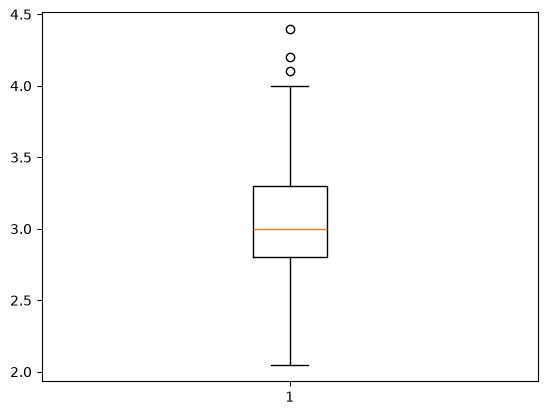

In [21]:
plt.boxplot(data['Sepal_Width'])   #handel the outliers
plt.show()

In [22]:
data.loc[data['Sepal_Width']> ub,'Sepal_Width']=ub

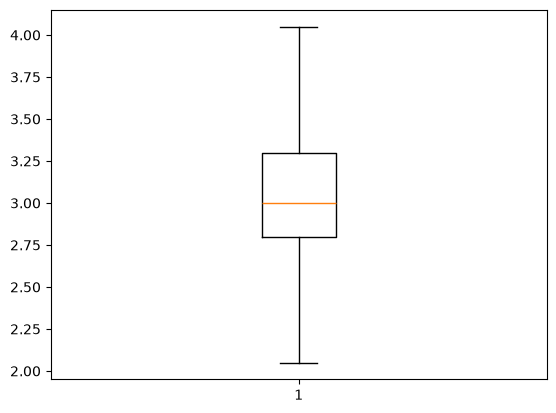

In [23]:
plt.boxplot(data['Sepal_Width'])   #handel the outliers
plt.show()

In [24]:
####Replace na value
median=data['Sepal_Width'].median()
data['Sepal_Width'].fillna(median)

0      3.5
1      3.0
2      3.2
3      3.1
4      3.6
      ... 
145    3.0
146    2.5
147    3.0
148    3.4
149    3.0
Name: Sepal_Width, Length: 150, dtype: float64

In [25]:
median=data['Sepal_Width'].median()
data['Sepal_Width']=data['Sepal_Width'].fillna(median)

#### Univariate analysis

<Axes: xlabel='Sepal_Length', ylabel='Count'>

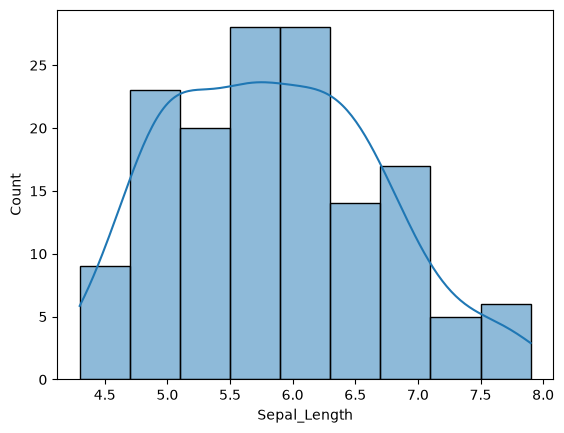

In [26]:
sns.histplot(data=data,x='Sepal_Length',kde=True)

#### Bivariate analysis

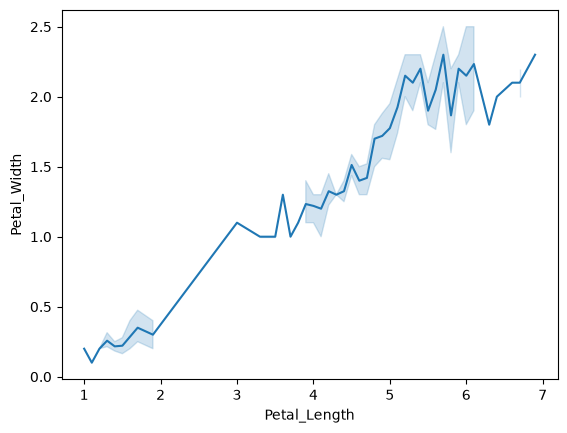

In [27]:
sns.lineplot(data, x='Petal_Length',y='Petal_Width')
plt.show()

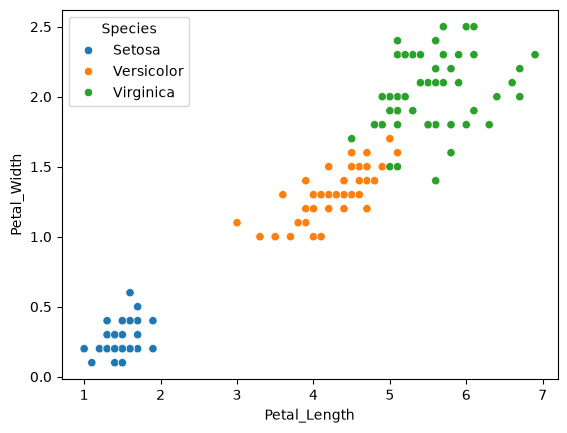

In [28]:
sns.scatterplot(data, x='Petal_Length',y='Petal_Width',hue='Species')
plt.show()

   #### 
       1.Setosa: Petal_Length:(1-2), Petal_Width:(0.1-0.5)
       2.Versicolor: Petal_Length:(3-5), Petal_Width:(1-1.5)
       3.Virginica: Petal_Length:(>5), Petal_Width:(>1.5)

#### Multivariate analysis

In [29]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal_Length  150 non-null    float64
 1   Sepal_Width   150 non-null    float64
 2   Petal_Length  150 non-null    float64
 3   Petal_Width   150 non-null    float64
 4   Species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [30]:
data3=data.drop('Species',axis=1)

In [31]:
data3.corr()

,Sepal_Length,Sepal_Width,Petal_Length,Petal_Width
Sepal_Length,1.000000,-0.110343,0.871754,0.817954
Sepal_Width,-0.110343,1.000000,-0.419823,-0.355582
Petal_Length,0.871754,-0.419823,1.000000,0.962757
Petal_Width,0.817954,-0.355582,0.962757,1.000000


<Axes: >

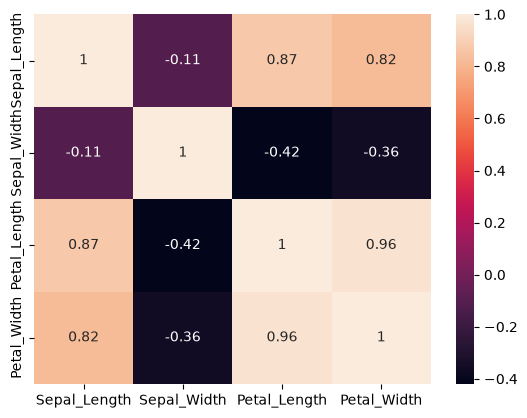

In [33]:
sns.heatmap(data3.corr(),annot=True)